In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

from analysis import *

In [2]:
%%capture root_dir
!git rev-parse --show-toplevel
# Get the root directory for the github repo

In [3]:
# setup variables
param_1 = 'Match proportion'
param_2 = 'Trim quality'
output_folder = 'OUTPUT_MP_TQ_extracted'

In [4]:
# Read directory dictionary
parameters_df = pd.read_csv(f'{output_folder}/parameters.csv').drop_duplicates().set_index('Directory name')
parameters_df.head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4
Simulated_deletion_MP0.75_MC25_TQ13_TW4-OUTPUT,0.75,25,13,4
Simulated_deletion_MP0.75_MC25_TQ14_TW4-OUTPUT,0.75,25,14,4
Simulated_deletion_MP0.75_MC25_TQ15_TW4-OUTPUT,0.75,25,15,4
Simulated_deletion_MP0.75_MC25_TQ16_TW4-OUTPUT,0.75,25,16,4


In [5]:
output_dirs = []
for dir in parameters_df.index:
    output_dirs.append(dir)

In [6]:
# Read and append data
allreadcounts_dfs = []
for dir in output_dirs:
    dirs = os.listdir(f'{output_folder}/{dir}')
    for i in range(len(dirs)):
        if not os.path.isdir(f'{output_folder}/{dir}/{dirs[i]}'):
            continue
        allreadcounts_dfs.append(pd.read_csv(f'{output_folder}/{dir}/{dirs[i]}/{dirs[i]}.allReadCounts', sep='\t'))
        allreadcounts_dfs[-1]['Directory name'] = dir
        allreadcounts_dfs[-1]['Fish'] = dirs[i]
allreadcounts_dfs[0].head()

,event,array,count,proportion,Directory name,Fish
0,57D+35_57D+35_57D+35_NONE_NONE_NONE_NONE_NONE_...,0,9442,0.248402,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1
1,3D+37_39D+60_39D+60_9D+115_NONE_NONE_NONE_NONE...,1,7073,0.186078,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1
2,84D+34_84D+34_84D+34_84D+34_NONE_NONE_1I+199+A...,2,5708,0.150167,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1
3,3D+37_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,3,5069,0.133356,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1
4,3D+37_27D+67_27D+67_9D+115_NONE_NONE_NONE_NONE...,4,2731,0.071848,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1


In [7]:
results_df = pd.concat(allreadcounts_dfs)
print(results_df.info())
for col in parameters_df.columns:
    results_df[col] = results_df['Directory name'].map(parameters_df[col]) # Map parameter values
results_df.head()

<class 'pandas.DataFrame'>
Index: 168986 entries, 0 to 472
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   event           168986 non-null  str    
 1   array           168986 non-null  int64  
 2   count           168986 non-null  int64  
 3   proportion      168986 non-null  float64
 4   Directory name  168986 non-null  str    
 5   Fish            168986 non-null  str    
dtypes: float64(1), int64(2), str(3)
memory usage: 9.0 MB
None


,event,array,count,proportion,Directory name,Fish,Match proportion,Match count,Trim quality,Trim window
0,57D+35_57D+35_57D+35_NONE_NONE_NONE_NONE_NONE_...,0,9442,0.248402,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1,0.75,25,12,4
1,3D+37_39D+60_39D+60_9D+115_NONE_NONE_NONE_NONE...,1,7073,0.186078,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1,0.75,25,12,4
2,84D+34_84D+34_84D+34_84D+34_NONE_NONE_1I+199+A...,2,5708,0.150167,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1,0.75,25,12,4
3,3D+37_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,3,5069,0.133356,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1,0.75,25,12,4
4,3D+37_27D+67_27D+67_9D+115_NONE_NONE_NONE_NONE...,4,2731,0.071848,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,fish38_s6_rep1,0.75,25,12,4


In [8]:
# Calculate the singleton entry proportion and pearson skew for each combination of parameters
info_df = results_df.groupby([param_1, param_2]).agg(
    total_entries=('count', 'sum'),
    ).reset_index()
count_ones = (
    results_df[results_df['count'] == 1]  # Filter rows where count == 1
    .groupby([param_1, param_2])  # Group by both columns
    .size()  # Count occurrences per group
    .reset_index(name='singleton_entries')  # Convert to DataFrame
)
count_ones.head()
info_df = info_df.merge(
    count_ones,  
    on=[param_1, param_2],  # Match these columns
    how='left'  # Keep all rows from info_df (fill NaN if no match)
)
info_df['singleton_entry_proportion'] = info_df['singleton_entries'] / info_df['total_entries']
info_df.head()

,Match proportion,Trim quality,total_entries,singleton_entries,singleton_entry_proportion
0,0.75,12,216114,4499,0.020818
1,0.75,13,222645,7558,0.033946
2,0.75,14,226423,8995,0.039727
3,0.75,15,218588,6062,0.027733
4,0.75,16,206049,3220,0.015627


In [9]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

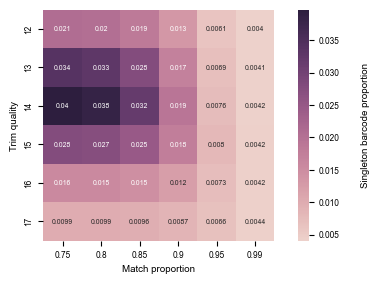

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))

# Generate heatmap
pivot_data = info_df.pivot(index=param_2, columns=param_1, values="singleton_entry_proportion")
sb.heatmap(pivot_data, annot=True, square=True, cmap=sb.cubehelix_palette(as_cmap=True), ax=ax,
          annot_kws={"size": 5})

# plt.title('Singleton barcode proportion')

cbar = ax.collections[0].colorbar
cbar.set_label("Singleton barcode proportion", labelpad = 15)
# plt.subplots_adjust(left=0.3) 

# Show the plot
# plt.tight_layout()  # Prevent label cutoff
plt.savefig('images/singleton_proportion.png', dpi = 300, bbox_inches = 'tight')
plt.savefig('images/singleton_proportion.svg', bbox_inches = 'tight')
plt.show()